In [1]:
# Imports and shared helpers
import pandas as pd
from catboost import CatBoostClassifier
import json
import pickle
import numpy as np
from insights_utils import (get_catboost_proba, compute_divergence_scores, paths, compute_stylometric_features
                               ) 
from scipy.stats import spearmanr
from matplotlib import pyplot as plt

In [2]:
# Load main dataset and SPECTER embeddings
data = pd.read_csv(paths["Dataset"])
specter = pd.read_csv(paths["SPECTER"])


In [3]:
# Merge dataset with SPECTER embeddings on project_id
df = data.merge(specter, on="project_id", how="inner")


In [4]:
# Load the fixed train/val/test id split

with open(paths["split"], "r") as f:
    split = json.load(f)
    train_ids = split["train"]
    val_ids = split["val"]  
    test_ids = split["test"]

In [5]:
# Create combined text field for stylometric features and specter embeddings
df["combined_text"] = (
    df["title"].fillna("") + " " + df["abstract"].fillna("")
)

In [6]:
# Compute stylometric features from combined text
stylometric_df = df["combined_text"].apply(compute_stylometric_features)

In [7]:
# Attach stylometric feature columns
stylometric_cols = [
    "word_count",
    "sentence_count",
    "avg_word_length",
    "avg_sentence_length",
    "lexical_diversity",
    "complex_word_ratio"
]

df = pd.concat([df, stylometric_df[stylometric_cols]], axis=1)

print("Updated df shape:", df.shape)

Updated df shape: (131772, 785)


In [8]:
# Quick check: value probabilities for the first 3 rows
get_catboost_proba(df.iloc[:3])

array([0.47702   , 0.52456742, 0.41824166])

In [9]:
# Compute divergence and value

In [10]:
# Divergence score: mean distance to internal SPECTER neighbours
df["divergence_score"] = compute_divergence_scores(df,internal_dataset=True)

FAISS index built with 131772 vectors of dimension 768


In [11]:
# Summary of divergence scores
df["divergence_score"].describe()

count    131772.000000
mean          0.103370
std           0.026522
min           0.030840
25%           0.084780
50%           0.100013
75%           0.118118
max           0.313897
Name: divergence_score, dtype: float64

In [12]:
# Value score: CatBoost citation-impact probability for all rows
df["value_proba"]=get_catboost_proba(df)

In [13]:
# Shape check
df.shape

(131772, 787)

In [14]:
# Summary of value scores
df["value_proba"].describe()

count    131772.000000
mean          0.438729
std           0.196189
min           0.003609
25%           0.287095
50%           0.445854
75%           0.592302
max           0.920666
Name: value_proba, dtype: float64

In [15]:
#loading and merging entropy scores
ent=pd.read_csv(paths["Internal_Entropy"])
ent.head()

,project_id,entropy_score
0,0,2.890420
1,2,3.270022
2,3,2.872272
3,5,2.784906
4,6,3.007879


In [16]:
# Merge entropy, divergence and value into one scores table
combined_scores = ent.merge(df[["project_id", "divergence_score", "value_proba"]], on="project_id", how="inner")

In [17]:
# Preview combined scores
combined_scores.head()

,project_id,entropy_score,divergence_score,value_proba
0,0,2.890420,0.076746,0.477020
1,2,3.270022,0.129459,0.524567
2,3,2.872272,0.069265,0.418242
3,5,2.784906,0.101857,0.186017
4,6,3.007879,0.062902,0.587635


In [18]:
# Shape check
combined_scores.shape

(131772, 4)

In [19]:
# Persist combined scores to disk
combined_scores.to_csv(paths["Combined_Scores"], index=False)

In [20]:
# Summary of combined scores
combined_scores.describe()

,project_id,entropy_score,divergence_score,value_proba
count,131772.000000,131772.000000,131772.000000,131772.000000
mean,76075.874161,2.844023,0.103370,0.438729
std,43344.054573,0.380817,0.026522,0.196189
min,0.000000,1.514954,0.030840,0.003609
25%,38905.750000,2.593320,0.084780,0.287095
50%,77096.500000,2.813305,0.100013,0.445854
75%,113718.250000,3.055893,0.118118,0.592302
max,150105.000000,8.282290,0.313897,0.920666


In [21]:
# Reload combined scores (analysis starts here)
scores_df = pd.read_csv(paths["Combined_Scores"])

In [22]:
# Load the main dataset
data_df = pd.read_csv(paths["Dataset"])

In [23]:
# Preview
data_df.head()

,project_id,original_id,abstract,citation_count,publication_year,title,authors_str,source,original_id_clean
0,0,O02-2002,There is a need to measure word similarity whe...,14.0,2002,A Study on Word Similarity using Context Vecto...,"Chen, Keh-Jiann and\nYou, Jia-Ming",ACL,O02-2002
1,2,R13-1042,Thread disentanglement is the task of separati...,10.0,2013,"Headerless, Quoteless, but not Hopeless? Using...","Jamison, Emily and\nGurevych, Iryna",ACL,R13-1042
2,3,W05-0819,"In this paper, we describe a word alignment al...",15.0,2005,Aligning Words in {E}nglish-{H}indi Parallel C...,"Aswani, Niraj and\nGaizauskas, Robert",ACL,W05-0819
3,5,R13-1044,The paper 1 presents a rule-based approach to ...,2.0,2013,Recognizing semantic relations within {P}olish...,"K{\k{e}}dzia, Pawe{\l} and\nMaziarz, Marek",ACL,R13-1044
4,6,W05-0818,"In this paper we describe LIHLA, a lexical ali...",5.0,2005,{LIHLA}: Shared Task System Description,"Caseli, Helena M. and\nNunes, Maria G. V. an...",ACL,W05-0818


In [24]:
# Build combined title+abstract text field
data_df["combined_text"] = (
    data_df["title"].fillna("") + " " + data_df["abstract"].fillna("")
)

In [25]:
# Attach scores to each paper's text
combined_df = data_df[["project_id", "combined_text"]].merge(scores_df, on="project_id", how="inner")

In [26]:
# Preview
combined_df.head()

,project_id,combined_text,entropy_score,divergence_score,value_proba
0,0,A Study on Word Similarity using Context Vecto...,2.890420,0.076746,0.477020
1,2,"Headerless, Quoteless, but not Hopeless? Using...",3.270022,0.129459,0.524567
2,3,Aligning Words in {E}nglish-{H}indi Parallel C...,2.872272,0.069265,0.418242
3,5,Recognizing semantic relations within {P}olish...,2.784906,0.101857,0.186017
4,6,{LIHLA}: Shared Task System Description In thi...,3.007879,0.062902,0.587635


In [27]:
# Check for missing values
combined_df.isna().sum()

project_id          0
combined_text       0
entropy_score       0
divergence_score    0
value_proba         0
dtype: int64

In [28]:
# Slice out the 2025 test set and the validation set by id
test_df = combined_df[combined_df["project_id"].isin(test_ids)].copy()
val_df = combined_df[combined_df["project_id"].isin(val_ids)].copy()

In [29]:
# Inspect the test set
test_df

,project_id,combined_text,entropy_score,divergence_score,value_proba
63616,74708,Hagen-Poiseuille Flow Linear Stability Paradox...,3.957755,0.128616,0.260086
64274,75370,Thermodynamics: Extending and Reconstructing o...,3.045077,0.076982,0.154117
65470,76640,Defining implication relation for classical lo...,2.675335,0.131465,0.337897
70469,82138,Geospatial distributions reflect rates of evol...,2.842212,0.114112,0.257077
70519,82194,Revisiting the charging-capacitor problem Th...,2.857491,0.159294,0.081979
...,...,...,...,...,...
129650,147968,Do Visual Imaginations Improve Vision-and-Lang...,3.134986,0.094241,0.663760
129651,147969,The Emperor's New Clothes in Benchmarking? A R...,2.887447,0.084125,0.590812
129652,147970,Survey on Evaluation of LLM-based Agents The...,2.492774,0.096552,0.598322
129653,147971,Stop Overthinking: A Survey on Efficient Reaso...,2.743347,0.064426,0.700213


In [30]:
# Summary of the three axes on the test set
test_df[["value_proba", "divergence_score", "entropy_score"]].describe()

,value_proba,divergence_score,entropy_score
count,6958.000000,6958.000000,6958.000000
mean,0.541863,0.098114,2.767785
std,0.163331,0.023613,0.295013
min,0.057629,0.039426,1.671307
25%,0.431429,0.081670,2.566757
50%,0.556677,0.094436,2.755893
75%,0.667518,0.111195,2.954089
max,0.901750,0.263971,4.738440


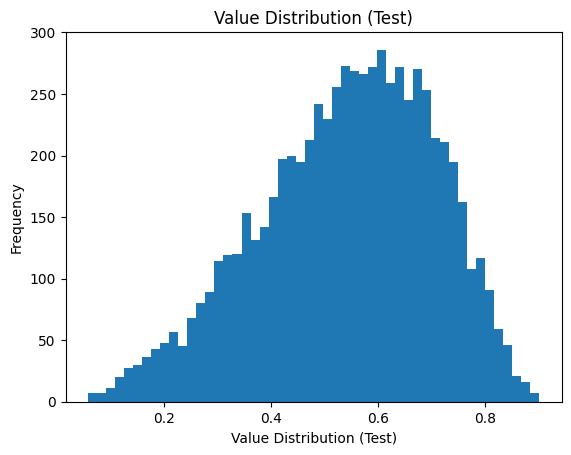

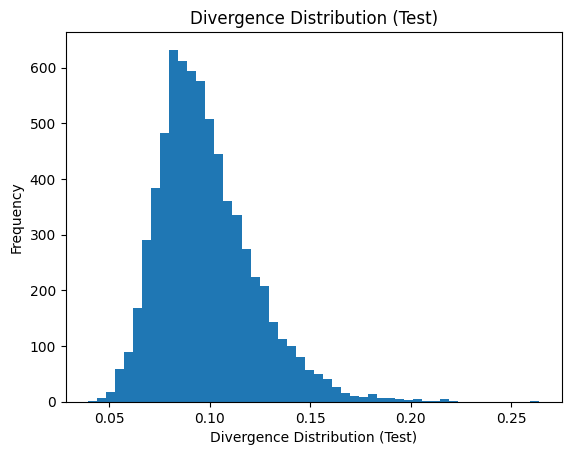

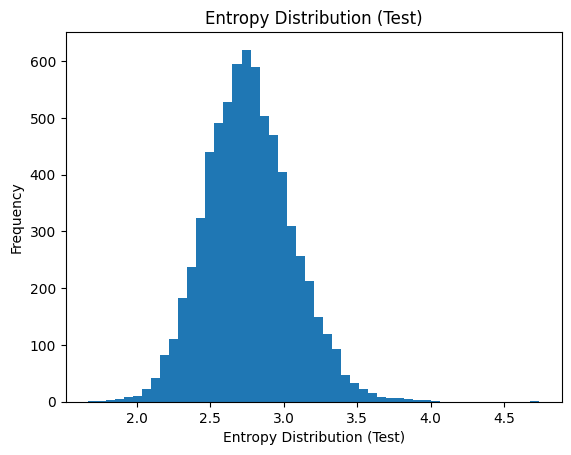

In [31]:
#insights
def plot_distribution(data, title):
    plt.figure()
    plt.hist(data, bins=50)
    plt.title(title)
    plt.xlabel(title)
    plt.ylabel("Frequency")
    plt.show()
plot_distribution(test_df["value_proba"], "Value Distribution (Test)")
plot_distribution(test_df["divergence_score"], "Divergence Distribution (Test)")
plot_distribution(test_df["entropy_score"], "Entropy Distribution (Test)")

In [32]:
# Helper: Spearman correlation + p-value
def compute_corr(x, y):
    rho, p = spearmanr(x, y)
    return rho, p

In [33]:
# Pairwise Spearman correlations among the three axes (test set)
pairs = [
    ("value_proba", "divergence_score"),
    ("value_proba", "entropy_score"),
    ("entropy_score", "divergence_score")
]

results = []

for x, y in pairs:
    rho, p = compute_corr(test_df[x], test_df[y])
    results.append({
        "pair": f"{x} vs {y}",
        "rho": rho,
        "p_value": p
    })

corr_df = pd.DataFrame(results)
corr_df

,pair,rho,p_value
0,value_proba vs divergence_score,-0.430377,0.000000e+00
1,value_proba vs entropy_score,-0.013289,2.677191e-01
2,entropy_score vs divergence_score,0.242612,9.187074e-94


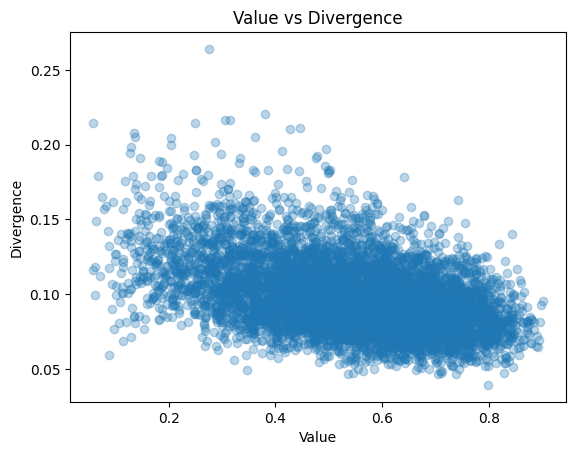

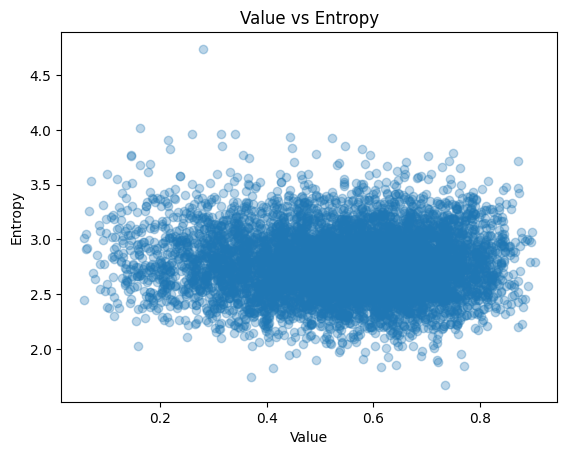

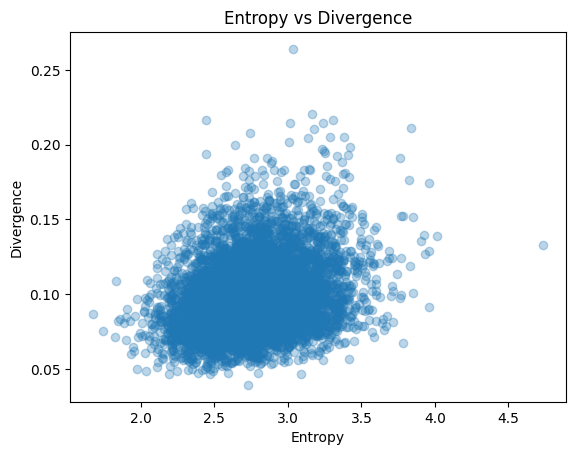

In [34]:
# Scatter plots for each pair of axes
def scatter_plot(x, y, xlabel, ylabel):
    plt.figure()
    plt.scatter(x, y, alpha=0.3)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(f"{xlabel} vs {ylabel}")
    plt.show()

scatter_plot(test_df["value_proba"], test_df["divergence_score"], "Value", "Divergence")
scatter_plot(test_df["value_proba"], test_df["entropy_score"], "Value", "Entropy")
scatter_plot(test_df["entropy_score"], test_df["divergence_score"], "Entropy", "Divergence")

In [35]:
# Compare divergence/entropy between top-20% and bottom-20% value papers
top = test_df[test_df["value_proba"] >= test_df["value_proba"].quantile(0.8)]
bottom = test_df[test_df["value_proba"] <= test_df["value_proba"].quantile(0.2)]

print("Top value divergence mean:", top["divergence_score"].mean())
print("Bottom value divergence mean:", bottom["divergence_score"].mean())

print("Top value entropy mean:", top["entropy_score"].mean())
print("Bottom value entropy mean:", bottom["entropy_score"].mean())

Top value divergence mean: 0.08580337184267241
Bottom value divergence mean: 0.11490478207040229
Top value entropy mean: 2.7781495006605126
Bottom value entropy mean: 2.7987235818786185


In [36]:
# Overlap between the top-10% value and top-10% divergence sets
value_thresh = test_df["value_proba"].quantile(0.9)
div_thresh = test_df["divergence_score"].quantile(0.9)

top_value = test_df[test_df["value_proba"] >= value_thresh]
top_div = test_df[test_df["divergence_score"] >= div_thresh]

overlap = test_df[
    (test_df["value_proba"] >= value_thresh) &
    (test_df["divergence_score"] >= div_thresh)
]

print("Top value:", len(top_value))
print("Top divergence:", len(top_div))
print("Overlap:", len(overlap))
print("Overlap %:", len(overlap) / len(test_df))

Top value: 696
Top divergence: 696
Overlap: 5
Overlap %: 0.0007185972980741593


In [37]:
# Correlations among the three axes on val and test
def compute_all_corr(df):
    results = {}
    results["value_div"] = spearmanr(df["value_proba"], df["divergence_score"])[0]
    results["value_ent"] = spearmanr(df["value_proba"], df["entropy_score"])[0]
    results["ent_div"] = spearmanr(df["entropy_score"], df["divergence_score"])[0]
    return results

val_corr = compute_all_corr(val_df)
test_corr = compute_all_corr(test_df)

print("Validation correlations:", val_corr)
print("Test correlations:", test_corr)

Validation correlations: {'value_div': np.float64(-0.4633296563182908), 'value_ent': np.float64(-0.05010286261972804), 'ent_div': np.float64(0.2566675706728819)}
Test correlations: {'value_div': np.float64(-0.4303770023309241), 'value_ent': np.float64(-0.013288806246385567), 'ent_div': np.float64(0.24261218825780656)}


In [38]:
# Print the top-3 papers by value and by divergence
high_value = test_df.sort_values(by="value_proba", ascending=False).head(3)
high_div = test_df.sort_values(by="divergence_score", ascending=False).head(3)

def print_examples(df_subset, title):
    print(f"\n===== {title} =====\n")
    for _, row in df_subset.iterrows():
        print(f"Value: {row['value_proba']:.3f} | Div: {row['divergence_score']:.3f}")
        print(row["combined_text"][:500])
        print("-" * 80)

print_examples(high_value, "High Value Papers")
print_examples(high_div, "High Divergence Papers")


===== High Value Papers =====

Value: 0.902 | Div: 0.096
Predicting the Performance of Black-box LLMs through Self-Queries   As large language models (LLMs) are increasingly relied on in AI systems,
predicting when they make mistakes is crucial. While a great deal of work in
the field uses internal representations to interpret model behavior, these
representations are inaccessible when given solely black-box access through an
API. In this paper, we extract features of LLMs in a black-box manner by using
follow-up prompts and taking the probabilities o
--------------------------------------------------------------------------------
Value: 0.897 | Div: 0.093
RedStar: Does Scaling Long-CoT Data Unlock Better Slow-Reasoning
  Systems?   Can scaling transform reasoning? In this work, we explore the untapped
potential of scaling Long Chain-of-Thought (Long-CoT) data to 1000k samples,
pioneering the development of a slow-thinking model, RedStar. Through extensive
experiments with various LLM